<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDS0321ENSkillsNetwork26802033-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# **SpaceX  Falcon 9 First Stage Landing Prediction**


## Assignment: Exploring and Preparing Data


Estimated time needed: **70** minutes


In this assignment, we will predict if the Falcon 9 first stage will land successfully. SpaceX advertises Falcon 9 rocket launches on its website with a cost of 62 million dollars; other providers cost upward of 165 million dollars each, much of the savings is due to the fact that SpaceX can reuse the first stage.

In this lab, you will perform Exploratory Data Analysis and Feature Engineering.


Falcon 9 first stage will land successfully


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/landing_1.gif)


Several examples of an unsuccessful landing are shown here:


![](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DS0701EN-SkillsNetwork/api/Images/crash.gif)


Most unsuccessful landings are planned. Space X performs a controlled landing in the oceans.


## Objectives

Perform exploratory Data Analysis and Feature Engineering using `Pandas` and `Matplotlib`

*   Exploratory Data Analysis
*   Preparing Data  Feature Engineering


### Import Libraries and Define Auxiliary Functions


We will import the following libraries the lab


In [52]:
import piplite
await piplite.install(['seaborn'])

In [53]:
# pandas is a software library written for the Python programming language for data manipulation and analysis.
import pandas as pd
#NumPy is a library for the Python programming language, adding support for large, multi-dimensional arrays and matrices, along with a large collection of high-level mathematical functions to operate on these arrays
import numpy as np
# Matplotlib is a plotting library for python and pyplot gives us a MatLab like plotting framework. We will use this in our plotter function to plot data.
import matplotlib.pyplot as plt
#Seaborn is a Python data visualization library based on matplotlib. It provides a high-level interface for drawing attractive and informative statistical graphics
import seaborn as sns

## Exploratory Data Analysis


First, let's read the SpaceX dataset into a Pandas dataframe and print its summary


In [54]:
from js import fetch
import io

URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
resp = await fetch(URL)
dataset_part_2_csv = io.BytesIO((await resp.arrayBuffer()).to_py())
df=pd.read_csv(dataset_part_2_csv)
df.head(5)

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


First, let's try to see how the `FlightNumber` (indicating the continuous launch attempts.) and `Payload` variables would affect the launch outcome.

We can plot out the <code>FlightNumber</code> vs. <code>PayloadMass</code>and overlay the outcome of the launch. We see that as the flight number increases, the first stage is more likely to land successfully. The payload mass also appears to be a factor; even with more massive payloads, the first stage often returns successfully.


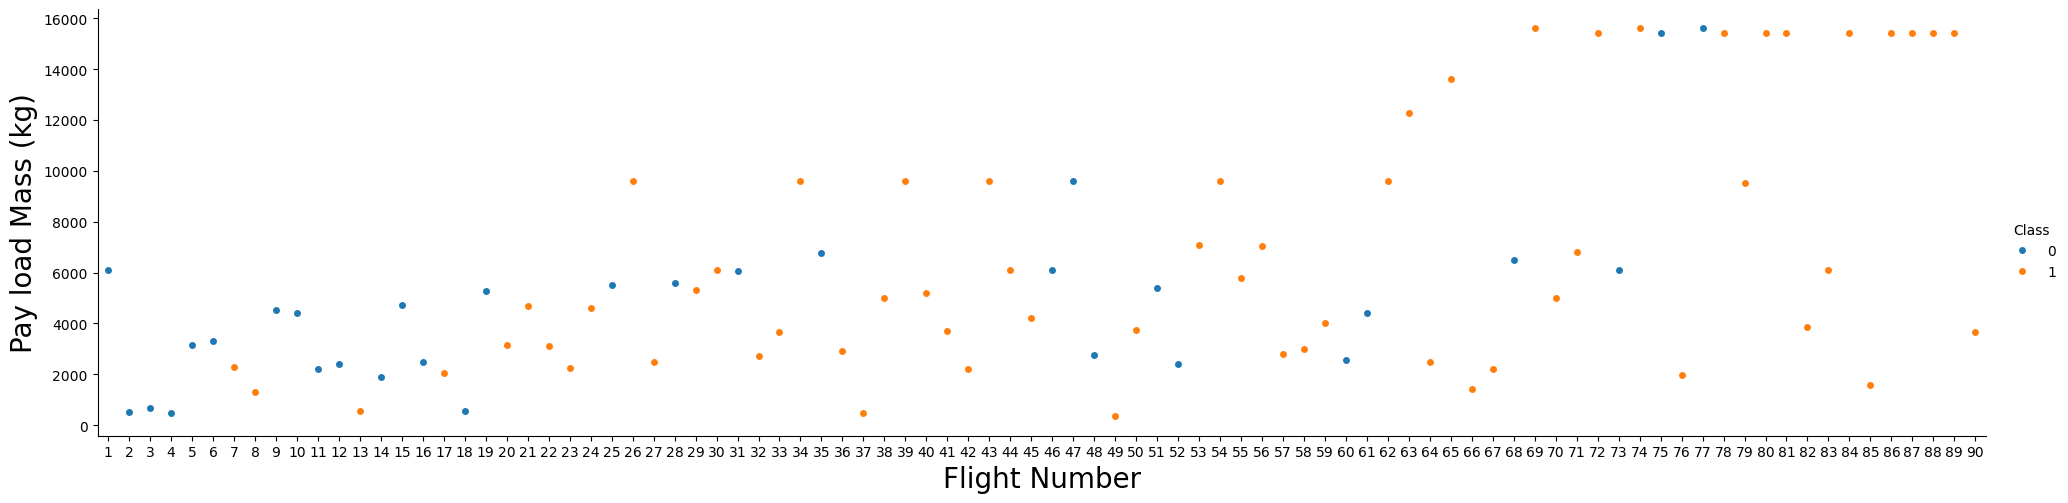

In [55]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect = 4)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Pay load Mass (kg)",fontsize=20)
plt.show()

In [83]:
fp_df = df[["FlightNumber", "PayloadMass"]]
fp_df1 = fp_df.iloc[60:90,]
print(fp_df1)

    FlightNumber   PayloadMass
60            61   4400.000000
61            62   9600.000000
62            63  12259.000000
63            64   2482.000000
64            65  13620.000000
65            66   1425.000000
66            67   2227.700000
67            68   6500.000000
68            69  15600.000000
69            70   5000.000000
70            71   6800.000000
71            72  15400.000000
72            73   6104.959412
73            74  15600.000000
74            75  15400.000000
75            76   1977.000000
76            77  15600.000000
77            78  15400.000000
78            79   9525.000000
79            80  15400.000000
80            81  15400.000000
81            82   3880.000000
82            83   6104.959412
83            84  15400.000000
84            85   1600.000000
85            86  15400.000000
86            87  15400.000000
87            88  15400.000000
88            89  15400.000000
89            90   3681.000000


Next, let's drill down to each site visualize its detailed launch records.


### TASK 1: Visualize the relationship between Flight Number and Launch Site


Use the function <code>catplot</code> to plot <code>FlightNumber</code> vs <code>LaunchSite</code>, set the  parameter <code>x</code>  parameter to <code>FlightNumber</code>,set the  <code>y</code> to <code>Launch Site</code> and set the parameter <code>hue</code> to <code>'class'</code>


In [57]:
df["LaunchSite"].unique()

array(['CCAFS SLC 40', 'VAFB SLC 4E', 'KSC LC 39A'], dtype=object)

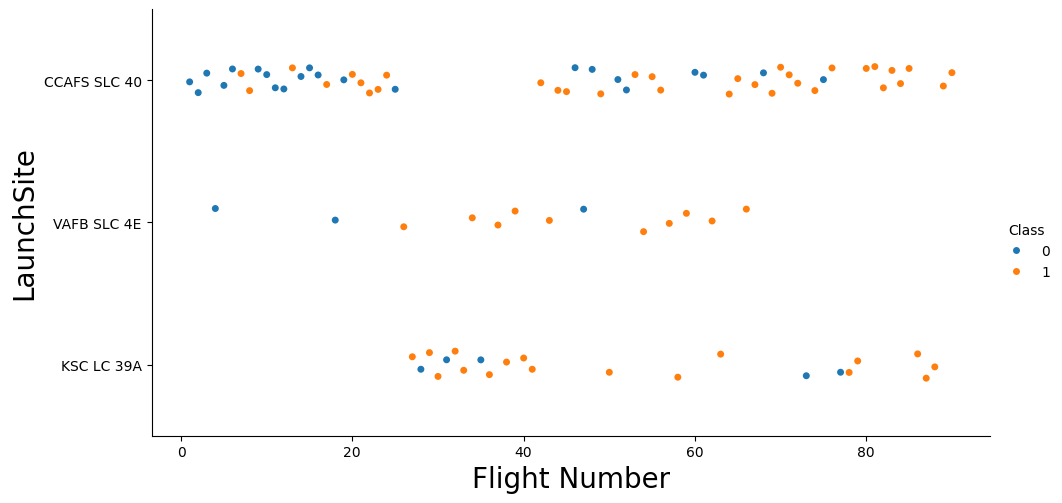

In [58]:
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect = 2)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("LaunchSite",fontsize=20)
plt.show()

In [59]:
fl_df = df[["FlightNumber", "LaunchSite"]]
fl_df1 = fl_df.iloc[25:41,]
print(fl_df1)

    FlightNumber   LaunchSite
25            26  VAFB SLC 4E
26            27   KSC LC 39A
27            28   KSC LC 39A
28            29   KSC LC 39A
29            30   KSC LC 39A
30            31   KSC LC 39A
31            32   KSC LC 39A
32            33   KSC LC 39A
33            34  VAFB SLC 4E
34            35   KSC LC 39A
35            36   KSC LC 39A
36            37  VAFB SLC 4E
37            38   KSC LC 39A
38            39  VAFB SLC 4E
39            40   KSC LC 39A
40            41   KSC LC 39A


In [60]:
fl_df1['LaunchSite'].value_counts()

LaunchSite
KSC LC 39A     12
VAFB SLC 4E     4
Name: count, dtype: int64

In [61]:
fl_df2 = fl_df.iloc[60:70,]
print(fl_df2)

    FlightNumber    LaunchSite
60            61  CCAFS SLC 40
61            62   VAFB SLC 4E
62            63    KSC LC 39A
63            64  CCAFS SLC 40
64            65  CCAFS SLC 40
65            66   VAFB SLC 4E
66            67  CCAFS SLC 40
67            68  CCAFS SLC 40
68            69  CCAFS SLC 40
69            70  CCAFS SLC 40


Each launch site was used in a different period. CCAFS SLC 40 has been the most frequently used site, from the early flights through a long period.
The apparent difference in success rate between launch sites seems to come from timing rather than the site itself: early flights are mostly 0 (many did not attempt a landing), while later flights are mostly 1 at every site.

発射場ごとの成功率の見かけの差は、発射場そのものではなく時期によるものと考えられる。初期の便は0が多く（着陸を試みていない便が多い）、後期はどの発射場でも1が多い。

Now try to explain the patterns you found in the Flight Number vs. Launch Site scatter point plots.


### TASK 2: Visualize the relationship between Payload Mass and Launch Site


We also want to observe if there is any relationship between launch sites and their payload mass.


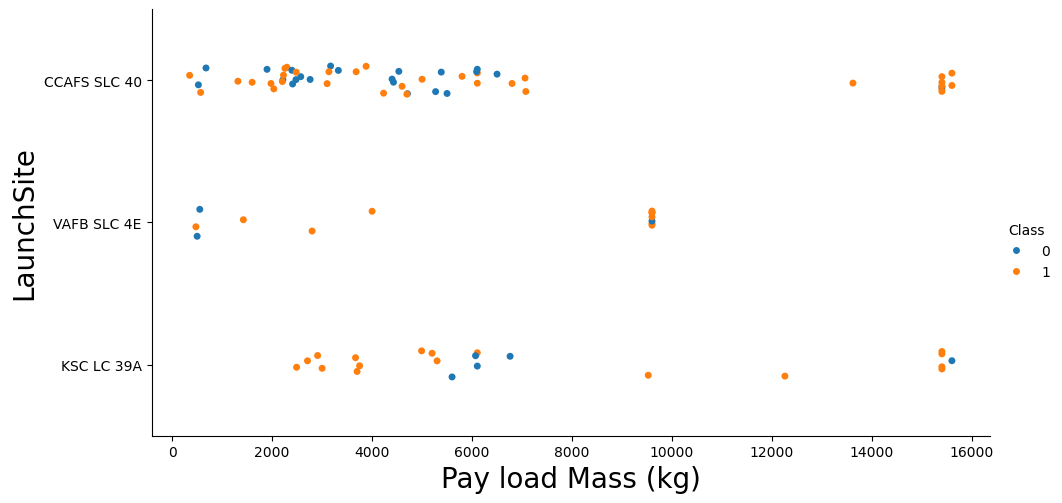

In [62]:
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect = 2)
plt.xlabel("Pay load Mass (kg)",fontsize=20)
plt.ylabel("LaunchSite",fontsize=20)
plt.show()

Now if you observe Payload Mass Vs. Launch Site scatter point chart you will find for the VAFB-SLC  launchsite there are no  rockets  launched for  heavypayload mass(greater than 10000).


### TASK  3: Visualize the relationship between success rate of each orbit type


Next, we want to visually check if there are any relationship between success rate and orbit type.


Let's create a `bar chart` for the sucess rate of each orbit


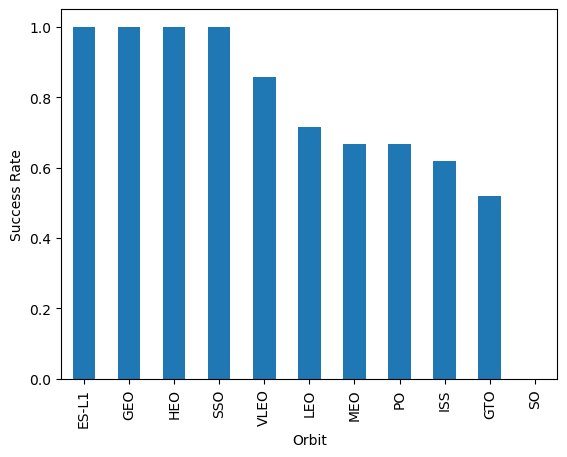

In [63]:
df.groupby('Orbit')['Class'].mean().sort_values(ascending=False).plot(kind='bar')
plt.xlabel("Orbit",fontsize=10)
plt.ylabel("Success Rate",fontsize=10)
plt.show()

In [64]:
df.groupby('Orbit')['Class'].agg(['mean', 'count'])

,mean,count
Orbit,,
ES-L1,1.000000,1
GEO,1.000000,1
GTO,0.518519,27
HEO,1.000000,1
ISS,0.619048,21
LEO,0.714286,7
MEO,0.666667,3
PO,0.666667,9
SO,0.000000,1


In [65]:
df.groupby('Orbit')['Class'].mean().sort_values(ascending=False)

Orbit
ES-L1    1.000000
GEO      1.000000
HEO      1.000000
SSO      1.000000
VLEO     0.857143
LEO      0.714286
MEO      0.666667
PO       0.666667
ISS      0.619048
GTO      0.518519
SO       0.000000
Name: Class, dtype: float64

ES-L1, GEO, and HEO each show a 100% success rate, but this should be interpreted with caution because each orbit had only one launch.
SSO is the only orbit with a 100% success rate across multiple launches (all 5 launches succeeded).
Among orbits with many launches, VLEO had a high success rate (about 86%), with 12 of 14 launches succeeding.

ES-L1、GEO、HEOの3つの軌道は成功率100%だが、飛行回数も1便のみのため慎重な解釈が必要。
SSOだけが複数回の打ち上げで成功率100%となっている（5便すべて成功）。
多くの便で高い成功率だった軌道はVLEO（成功率約86%）で、14便中12便が成功している。

Analyze the plotted bar chart to identify which orbits have the highest success rates.


### TASK  4: Visualize the relationship between FlightNumber and Orbit type


For each orbit, we want to see if there is any relationship between FlightNumber and Orbit type.


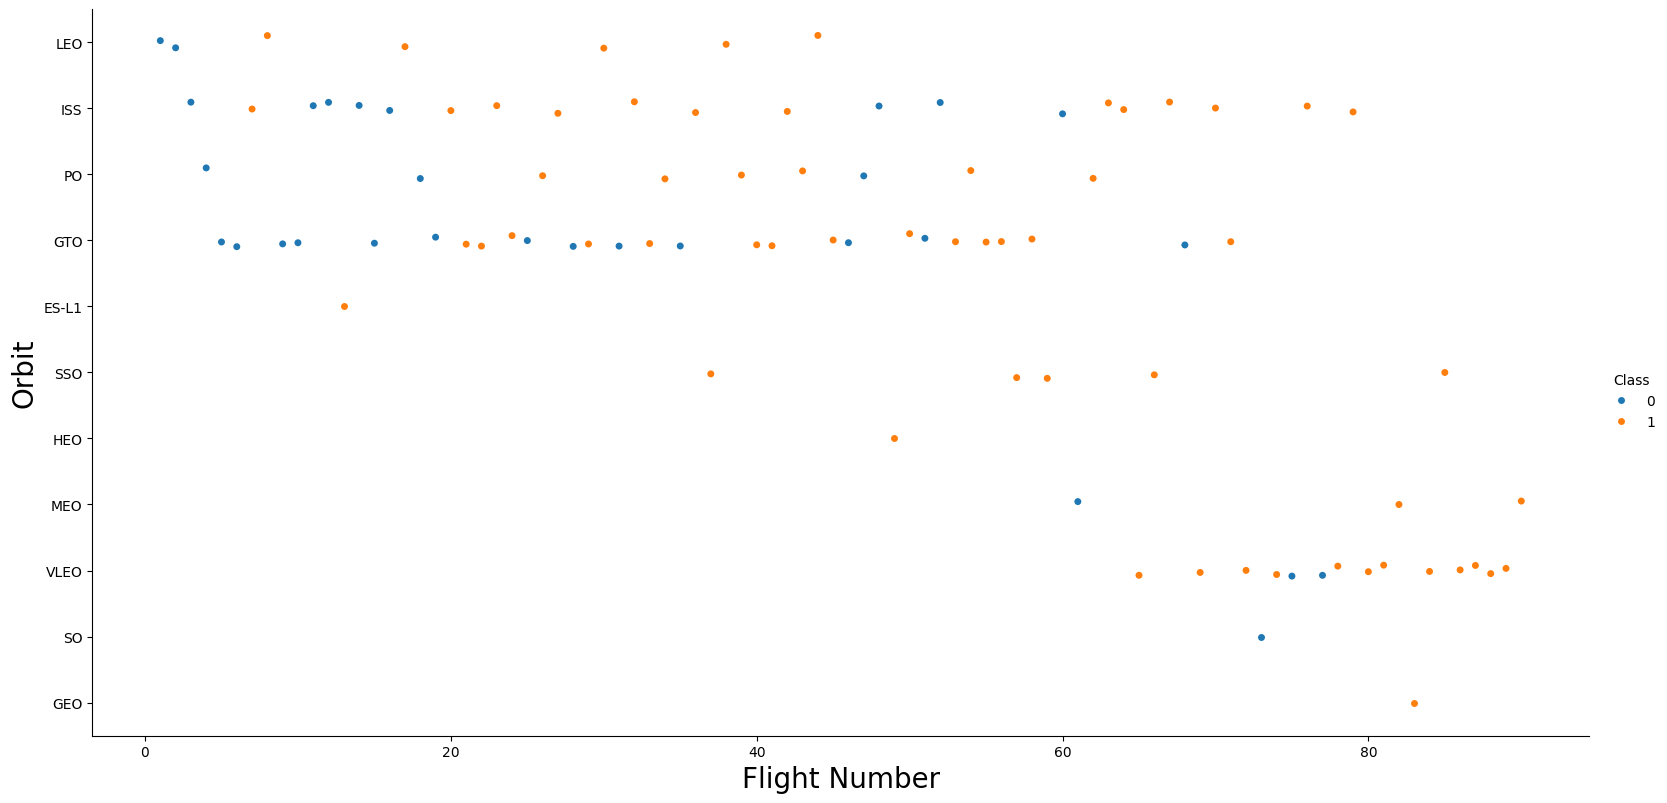

In [66]:
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect = 2, height = 8)
plt.xlabel("Flight Number",fontsize=20)
plt.ylabel("Orbit",fontsize=20)
plt.show()

In [67]:
# 着陸を試みていない便を取り出す
no_attempt = df[df['Outcome'].str.startswith('None')]
no_attempt['Outcome'].value_counts()

Outcome
None None    19
None ASDS     2
Name: count, dtype: int64

In [68]:
# 「試みたか」の列を作って、軌道と並べる
df['Attempted'] = ~df['Outcome'].str.startswith('None')      
pd.crosstab(df['Orbit'], df['Attempted']) 

Attempted,False,True
Orbit,,
ES-L1,0,1
GEO,0,1
GTO,12,15
HEO,0,1
ISS,4,17
LEO,2,5
MEO,1,2
PO,1,8
SO,1,0


In [69]:
# 各軌道の0と1の数を数える
pd.crosstab(df['Orbit'], df['Class'])

Class,0,1
Orbit,,
ES-L1,0,1
GEO,0,1
GTO,13,14
HEO,0,1
ISS,8,13
LEO,2,5
MEO,1,2
PO,3,6
SO,1,0


In LEO, only the first 2 of 7 flights are 0, so it may look as if landings became successful as the flight number increased. However, both of these flights did not attempt a landing, so this should be interpreted with caution.
In GTO, success also appears unrelated to flight number at first glance, but 12 of the 13 flights with Class 0 did not attempt a landing.
For the other orbits, it is difficult to judge any relationship because the number of flights is small (9 or fewer), and even ISS, with 21 flights, shows no clear relationship.
The only notable case is VLEO: its flights are concentrated only in the later period, all of them attempted a landing, and the success rate is high (about 86%).

LEOでは7便のうち最初の2便のみが0で、回数を重ねるごとに成功しているようにも見えるが、これはどちらも「着陸を試みていない」であるため、解釈は慎重に行う。
GTOも一見すると成功が飛行回数と関係がないように見えるが、0の13便中12便が「着陸を試みていない」便である。
他の軌道でも、飛行回数が少ない（9便以下）場合は関係が判断が難しく、飛行回数が21便のISSでもはっきりとした関係は見えない。
唯一、VLEOは飛行時期が全体の後期のみに集中しており、すべての便で着陸を試みて成功率も高い（成功率約86%）ことには注目しておきたい。

In [84]:
# 軌道ごとに、全体の便数・着陸を試みた便数・そのうち成功した便数を並べる
summary = df.groupby("Orbit").agg(
    Flights=("Class", "size"),                                          # 全体の便数
    Attempted=("Attempted", "sum"),                                     # 着陸を試みた便数
    Landed=("Class", "sum"),                                            # 着陸に成功した便数
)
summary["Rate_attempted"] = (summary["Landed"] / summary["Attempted"]).round(2)  # 試みた便だけの成功率
summary

,Flights,Attempted,Landed,Rate_attempted
Orbit,,,,
ES-L1,1,1,1,1.00
GEO,1,1,1,1.00
GTO,27,15,14,0.93
HEO,1,1,1,1.00
ISS,21,17,13,0.76
LEO,7,5,5,1.00
MEO,3,2,2,1.00
PO,9,8,6,0.75
SO,1,0,0,NaN


You can observe that in the LEO orbit, success seems to be related to the number of flights. Conversely, in the GTO orbit, there appears to be no relationship between flight number and success.


### TASK  5: Visualize the relationship between Payload Mass and Orbit type


Similarly, we can plot the Payload Mass vs. Orbit scatter point charts to reveal the relationship between Payload Mass and Orbit type


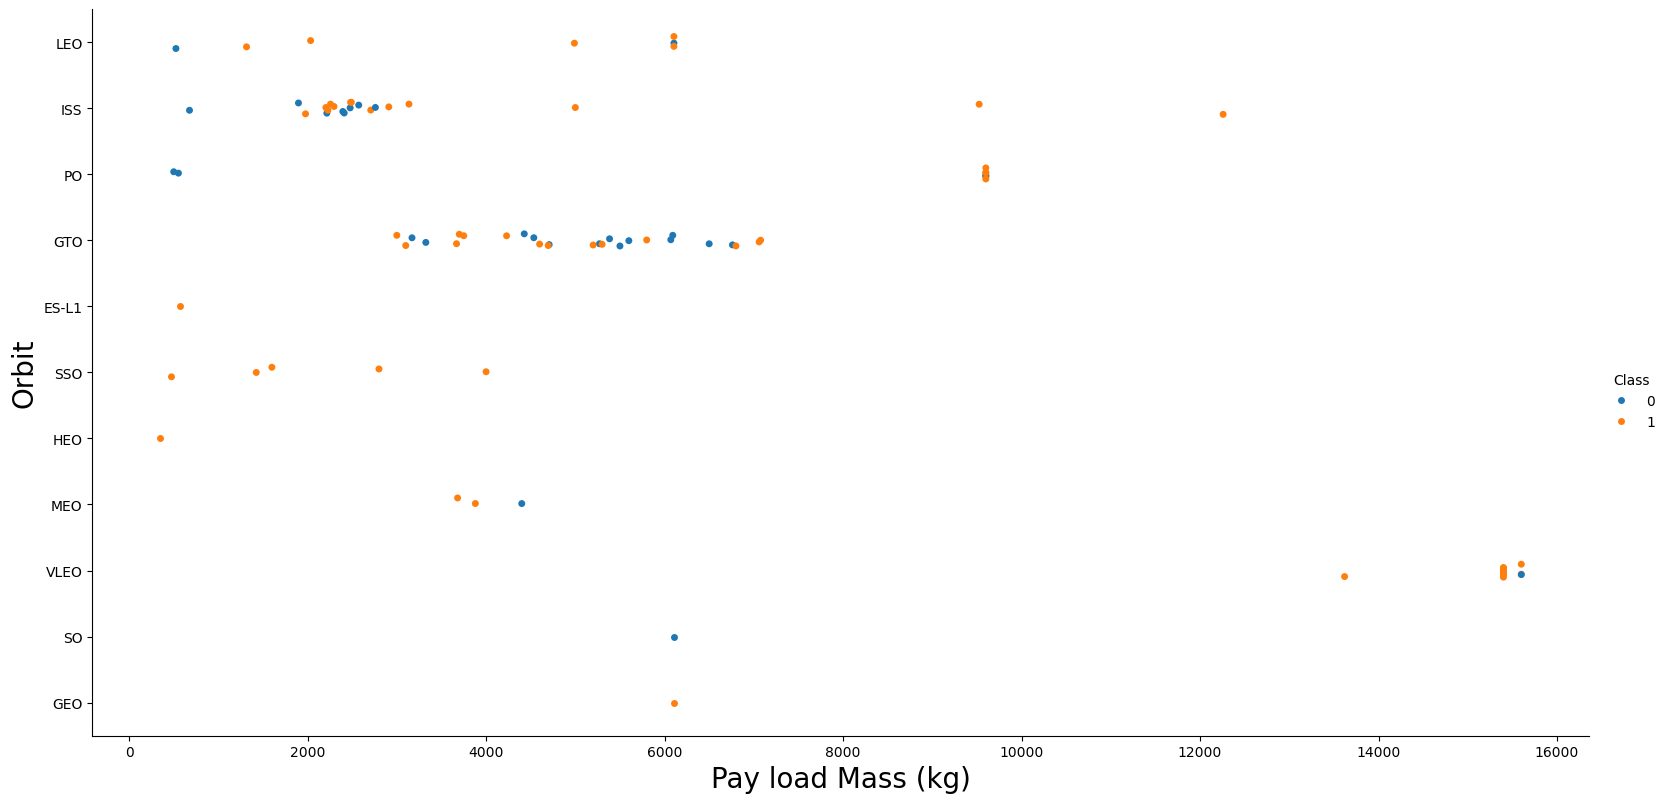

In [70]:
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect = 2, height = 8)
plt.xlabel("Pay load Mass (kg)",fontsize=20)
plt.ylabel("Orbit",fontsize=20)
plt.show()

It is difficult to judge the relationship between orbit, payload mass, and success rate, but there is a clear relationship between orbit and payload mass.
Heavy payloads (about 13,000 kg or more) are concentrated only in VLEO, while GTO payloads are concentrated in the range of about 3,000 to 7,000 kg, and ISS payloads in the range of about 2,000 to 3,000 kg.
All orbits other than ISS, PO, and VLEO carry payloads of about 7,000 kg or less.

軌道と積み荷の重さによる成功率についての関係性は判断が難しいが、軌道と積み荷の重さに関係性は見られる。
重い積み荷（約13,000Kg以上）はVLEOのみに集中しており、GTOは約3,000〜約7,000Kgの範囲、ISSは約2,000〜約3,000Kgの範囲に集中している。
ISS、PO、VLEO以外はすべて約7,000Kg以下の積み荷である。

With heavy payloads the successful landing or positive landing rate are more for Polar,LEO and ISS.

However, for GTO, it's difficult to distinguish between successful and unsuccessful landings as both outcomes are present.


### TASK  6: Visualize the launch success yearly trend


You can plot a line chart with x axis to be <code>Year</code> and y axis to be average success rate, to get the average launch success trend.


The function will help you get the year from the date:


In [71]:
# A function to Extract years from the date 
year=[]
def Extract_year():
    for i in df["Date"]:
        year.append(i.split("-")[0])
    return year
Extract_year()
df['Date'] = year
df.head()
    

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class,Attempted
0,1,2010,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0,False
1,2,2012,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0,False
2,3,2013,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0,False
3,4,2013,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0,True
4,5,2013,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0,False


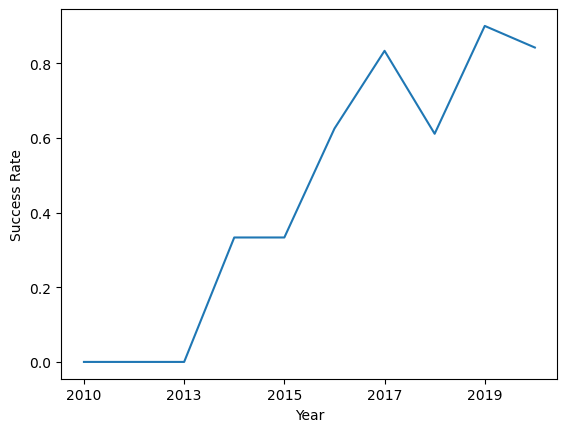

In [72]:
df.groupby('Date')['Class'].mean().plot(kind='line')
plt.xlabel("Year",fontsize=10)
plt.ylabel("Success Rate",fontsize=10)
plt.show()

In [86]:
# 年ごとに、全体の便数・着陸を試みた便数・そのうち成功した便数を並べる
summary_year = df.groupby("Date").agg(
    Flights=("Class", "size"),                                           # 全体の便数
    Attempted=("Attempted", "sum"),                                      # 着陸を試みた便数
    Landed=("Class", "sum"),                                             # 着陸に成功した便数
)
summary_year["Rate_attempted"] = (summary_year["Landed"] / summary_year["Attempted"]).round(2)  # 試みた便だけの成功率
summary_year

,Flights,Attempted,Landed,Rate_attempted
Date,,,,
2010,1,0,0,NaN
2012,1,0,0,NaN
2013,3,1,0,0.00
2014,6,3,2,0.67
2015,6,4,2,0.50
2016,8,7,5,0.71
2017,18,15,15,1.00
2018,18,12,11,0.92
2019,10,9,9,1.00


In [74]:
# 各年の0と1の数を数える
pd.crosstab(df['Date'], df['Class'])

Class,0,1
Date,,
2010,1,0
2012,1,0
2013,3,0
2014,4,2
2015,4,2
2016,3,5
2017,3,15
2018,7,11
2019,1,9


The success rate has increased overall, but there is a drop in 2018.
This drop is mainly because many flights in 2018 did not attempt a landing; among flights that attempted a landing, the success rate in 2018 was about 92%.

成功率は全体として上がっているが、2018年に落ち込みがある。
この落ち込みは主に、2018年に着陸を試みなかった便が多かったためで、着陸を試みた便だけで見ると2018年の成功率は約92%だった。

you can observe that the sucess rate since 2013 kept increasing till 2020


## Features Engineering


By now, you should obtain some preliminary insights about how each important variable would affect the success rate, we will select the features that will be used in success prediction in the future module.


In [75]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


### TASK  7: Create dummy variables to categorical columns


Use the function <code>get_dummies</code> and <code>features</code> dataframe to apply OneHotEncoder to the column <code>Orbits</code>, <code>LaunchSite</code>, <code>LandingPad</code>, and <code>Serial</code>. Assign the value to the variable <code>features_one_hot</code>, display the results using the method head. Your result dataframe must include all features including the encoded ones.


In [76]:
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


### TASK  8: Cast all numeric columns to `float64`


Now that our <code>features_one_hot</code> dataframe only contains numbers, cast the entire dataframe to variable type <code>float64</code>


In [77]:
features_one_hot = features_one_hot.astype('float64')
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6104.959412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4.0,500.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5.0,3170.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


We can now export it to a <b>CSV</b> for the next section,but to make the answers consistent, in the next lab we will provide data in a pre-selected date range.


In [78]:
features_one_hot.to_csv('dataset_part_3.csv', index=False)

## Authors


[Pratiksha Verma](https://www.linkedin.com/in/pratiksha-verma-6487561b1/)


<!--## Change Log-->


<!--
| Date (YYYY-MM-DD) | Version | Changed By      | Change Description      |
| ----------------- | ------- | -------------   | ----------------------- |
| 2022-11-09        | 1.0     | Pratiksha Verma | Converted initial version to Jupyterlite|
| 2024-07-18        | 1.2     | Anita Verma | Clarified instructions|
-->


### <h3 align="center"> IBM Corporation 2022. All rights reserved. <h3/>
